# Problem set 7: Exchange economies

**What you will practice**

* Extending a model you already know: a new **functional form**, more **consumers**, and CES preferences.
* Writing a **subclass** that only overrides what actually changes - and **filling in** a class from a skeleton.
* **Testing** your code with `assert` against cases you can already solve.
* Root-finding with `optimize.root_scalar`, and with two algorithms you write yourself.
* Discovering that a model can have **more than one equilibrium** - and that which one you find depends on the algorithm.
* Making figures with `fig` and `ax` that are easy to read.

**Answers.** After each question there is a cell like `import A1` + `A1.run()`. Write your own code first, then run the answer cell and compare.

**Table of contents**<a id='toc0_'></a>
- 1. [Supply and demand](#toc1_)
- 2. [Another functional form](#toc2_)
- 3. [An exchange economy with many consumers](#toc3_)
- 4. [More than one equilibrium](#toc4_)

<!-- vscode-jupyter-toc-config
	numbering=true
	anchor=true
	flat=false
	minLevel=2
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

In [1]:
%load_ext autoreload
%autoreload 2

from types import SimpleNamespace
from scipy import optimize
import numpy as np

import matplotlib.pyplot as plt
plt.rcParams.update({'axes.grid':True,'grid.color':'black','grid.alpha':'0.25','grid.linestyle':'-'})
plt.rcParams.update({'font.size':14})

colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

from exchange import ExchangeEconomy # the model from lecture 10

**The model from the lecture** is in the file [exchange.py](exchange.py) and was imported above. Use it as a **template** for your own classes - and as a **test** of your new formulas.

In [2]:
model_lecture = ExchangeEconomy()
print(model_lecture)
print('')
print(f'p1* = {model_lecture.equilibrium_price():.6f}')

Exchange economy with:
  alpha = 0.33 (A spends this share of her income on good 1)
  beta  = 0.67 (B spends this share of her income on good 1)
  wA    = (0.80,0.30) (what A owns)
  wB    = (0.20,0.70) (what B owns)

p1* = 0.944444


## 1. <a id='toc1_'></a>[Supply and demand](#toc0_)

Before returning to the exchange economy, a warm-up on the simplest market there is.

The **demand function** $D(p)$ says how much the buyers want at the price $p$, and the **supply function** $S(p)$ how much the sellers offer. We use straight lines,

$$ D(p) = a - bp, \qquad S(p) = c + dp $$

with $a=10$, $b=1$, $c=2$ and $d=1$. **Excess demand** is $Z(p) = D(p)-S(p)$, and the **equilibrium price** $p^{\ast}$ is where it is zero. Here it can be isolated by hand,

$$ p^{\ast} = \frac{a-c}{b+d} $$

which gives us something to test against.

**Question:**

1. Write the three functions `demand(p)`, `supply(p)` and `excess_demand(p)`.
2. Find $p^{\ast}$ with `optimize.root_scalar` and check with an `assert` that it agrees with the formula.
3. Write the **auction algorithm** from section 6 of the lecture as a function `tatonnement(p_guess,nu)` that returns the whole path of prices *and* whether it converged. Start from $p=5$ and try $\nu = 0.05, 0.10, 0.50$ and $1.10$.
4. Make a figure with two panels: the market (supply and demand, with $p^{\ast}$ marked) and the distance $|p_k-p^{\ast}|$ in the auction on a **log** y-axis.

Then explain what goes wrong for the largest $\nu$. Can you say *exactly* which step sizes work here?

**Hints:**

* `optimize.root_scalar(f,bracket=[0,20],method='brentq')`
* Plot the market with the quantity on the x-axis and the price on the y-axis: `ax.plot(demand(p_grid),p_grid)`.
* A log axis cannot show an exact zero. Use `np.fmax(np.abs(path-p_star),1e-16)`.
* Write the update $p_{k+1} = p_k + \nu Z(p_k)$ as a formula in $p_k-p^{\ast}$ and see what happens to the distance in each round.

In [3]:
# write your own code here

by hand      : p* = 4.00000000, q* = 6.0000
root-finder  : p* = 4.00000000 (2 iterations)

nu = 0.05: converged = True  after 183 prices, last price =       4.0000
nu = 0.10: converged = True  after  87 prices, last price =       4.0000
nu = 0.50: converged = True  after   2 prices, last price =       4.0000
nu = 1.10: converged = False after 201 prices, last price = 6858816903929258.0000


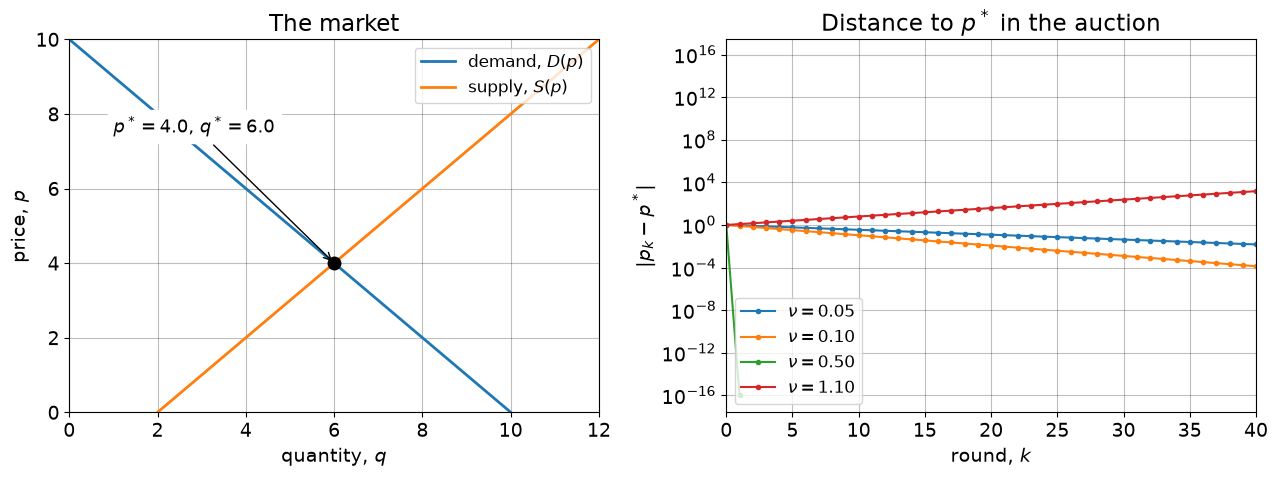


the auction only works when the step size is small enough:
here the new price is p + nu*(8-2p), so the distance to p* = 4 is
multiplied by 1-2*nu in every round. It only shrinks when |1-2*nu| < 1,
that is for nu < 1. With nu = 0.50 the factor is exactly 0, so the very
first round lands on p* - and with nu = 1.10 the price explodes.


In [4]:
import A1
A1.run()

## 2. <a id='toc2_'></a>[Another functional form](#toc0_)

Everything in the lecture rested on **one** choice: that the utility function was Cobb-Douglas. Here we keep the rest of the model exactly as it is - two consumers, one unit of each good, $p_2=1$ - and change only that choice.

Let both consumers have **quasi-linear** preferences,

$$ u^A(x_1,x_2) = a_A\sqrt{x_1} + x_2, \qquad u^B(x_1,x_2) = a_B\sqrt{x_1} + x_2 $$

They are called *quasi-linear* because they are linear in good 2. Good 1 still has falling marginal utility, $\frac{a}{2\sqrt{x_1}}$.

**Demand.** Insert the budget $x_2 = m-p_1x_1$ in the utility function and maximize over $x_1$ alone,

$$ \max_{x_1}\; a\sqrt{x_1} - p_1x_1 + m \qquad\Rightarrow\qquad \frac{a}{2\sqrt{x_1}} = p_1 $$

so that

$$ x_1(p_1) = \left(\frac{a}{2p_1}\right)^{2}, \qquad x_2(p_1,m) = m - p_1x_1(p_1) $$

**Look at that for a moment:** the demand for good 1 does not contain $m$. The income only decides how much is left for good 2.

**The equilibrium price.** Setting $x_1^A + x_1^B = 1$ and isolating $p_1$,

$$ \frac{a_A^2+a_B^2}{4p_1^2} = 1 \qquad\Rightarrow\qquad \boxed{\;p_1^{\ast} = \frac{\sqrt{a_A^2+a_B^2}}{2}\;} $$

**Calibration.** $a_A = 1$ and $a_B = 1.5$, and the endowments are the same as in the lecture, $\omega^A = (0.8,0.3)$.

**Question:** Write a class `QuasiLinearEconomy` that **inherits** from `ExchangeEconomy` and overrides *only* the five methods that actually change: `utility_A`, `utility_B`, `demand_A`, `demand_B` and `equilibrium_price`.

Everything else - `excess_demand`, `solve`, `solve_equilibrium_price` and `tatonnement` - you get for free, because those methods never do anything but call the ones you just replaced. Check that this is true:

1. **Test it:** the formula and the *inherited* `solve_equilibrium_price()` must give the same price.
2. **Test it again:** Walras' law, $p_1\varepsilon_1+\varepsilon_2 = 0$, must still hold at every price, and both markets must clear in equilibrium.
3. Make a figure with two panels: excess demand against the price, and the equilibrium price as a function of $\omega_1^A$ - with the **lecture model** drawn in the same panel for comparison.

Then explain what you see in the right-hand panel. Which line in the formulas above is responsible for it?

**Hints:**

* Inheritance: `class QuasiLinearEconomy(ExchangeEconomy):`, and in `__init__` set the new parameters `self.aA` and `self.aB` *first*, then call `super().__init__(**kwargs)`.
* You may also want to override `__str__`, since the inherited one prints `alpha` and `beta`, which no longer mean anything.
* One economy per endowment: `[QuasiLinearEconomy(w1A=w1A).equilibrium_price() for w1A in w1A_grid]`, and the same with `ExchangeEconomy` for the comparison.
* The methods only do arithmetic, so `model.excess_demand(p1_grid)` works on the whole grid of prices at once - exactly as in section 4.1 of the lecture.

In [5]:
# write your own code here

Exchange economy with quasi-linear preferences:
  aA = 1.00 (A's taste for good 1)
  aB = 1.50 (B's taste for good 1)
  wA = (0.80,0.30) (what A owns)
  wB = (0.20,0.70) (what B owns)

p1* (by hand)     = 0.9013878189
p1* (root-finder) = 0.9013878189

all tests passed

A consumes (0.3077,0.7438) and had (0.80,0.30)
B consumes (0.6923,0.2562) and had (0.20,0.70)
A: 1.1944 -> 1.2985, B: 1.3708 -> 1.5043


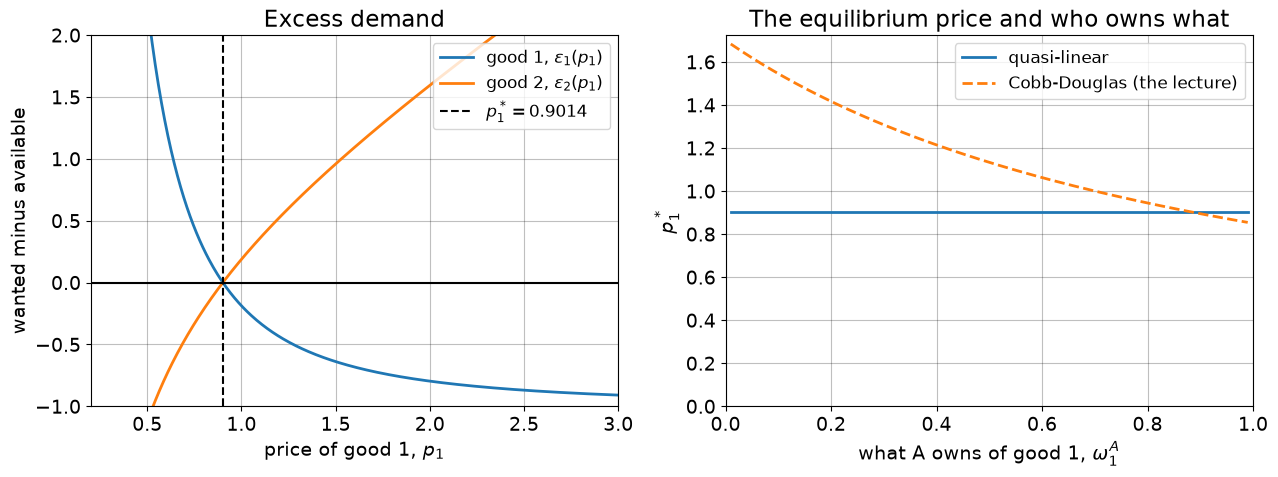


the whole point of the new functional form is in the formula for the demand for
good 1: it contains no m at all. Whatever A is given, she wants exactly the same
amount of good 1 - the endowment only changes how much of good 2 is left over.

so the equilibrium price is a flat line: it depends on the two tastes and on
nothing else. In the lecture model it falls from 1.68 to 0.85 across the same
grid. Note that we did not have to change a single line of the machinery to find
this out - excess_demand, solve, solve_equilibrium_price and tatonnement were all
inherited and worked unchanged, because they only ever call demand_A and demand_B.


In [6]:
import A2
A2.run()

## 3. <a id='toc3_'></a>[An exchange economy with many consumers](#toc0_)

In the lecture there were exactly **two** consumers. Now there are $N$ of them, $i=1,2,\dots,N$. Everything else is the same:

* consumer $i$ has preferences $u^i(x_1,x_2) = x_1^{\alpha_i}x_2^{1-\alpha_i}$ and owns $(\omega_{1i},\omega_{2i})$
* the price of good 2 is still $p_2 = 1$
* consumer $i$'s income is $m_i = p_1\omega_{1i}+\omega_{2i}$, and her demand is

$$ x_{1i}(p_1) = \alpha_i\frac{m_i}{p_1}, \qquad x_{2i}(p_1) = (1-\alpha_i)\,m_i $$

The **totals** are no longer one of each good but whatever the consumers happen to own together,

$$ W_1 = \sum_{i=1}^N \omega_{1i}, \qquad W_2 = \sum_{i=1}^N \omega_{2i} $$

so **excess demand** is

$$ \varepsilon_1(p_1) = \sum_{i=1}^N x_{1i}(p_1) - W_1, \qquad \varepsilon_2(p_1) = \sum_{i=1}^N x_{2i}(p_1) - W_2 $$

Setting $\varepsilon_1 = 0$ and isolating $p_1$ exactly as in the lecture gives

$$ p_1^{\ast} = \frac{\sum_i \alpha_i\omega_{2i}}{\sum_i (1-\alpha_i)\omega_{1i}} $$

which is the formula from the lecture with the two consumers replaced by $N$ of them.

**The economy used below:**

| $i$ | $\alpha_i$ | $\omega_{1i}$ | $\omega_{2i}$ | |
| --- | --- | --- | --- | --- |
| 1 | 0.20 | 0.90 | 0.10 | owns good 1, wants good 2 |
| 2 | 0.30 | 0.60 | 0.30 | |
| 3 | 0.60 | 0.30 | 0.60 | |
| 4 | 0.80 | 0.10 | 0.90 | owns good 2, wants good 1 |

**Question:** The class below is `ExchangeEconomy` from [exchange.py](exchange.py) rewritten for $N$ consumers. Everything is already in place except **four methods**, and each of them is a **single line**. Fill them in.

The only two changes from the lecture are that `self.alpha` becomes the array `self.alphas`, and that *"A plus B"* becomes a **sum over consumers**.

Then:

1. **Test it:** with $N=2$ and the parameters of the lecture model, your class must give exactly the same price *and* the same allocation as `ExchangeEconomy`.
2. **Test it again:** Walras' law, $p_1\varepsilon_1+\varepsilon_2 = 0$, must hold at every price.
3. **Use it:** solve the economy in the table and make a **bar chart** of what each consumer *owns* and what she *consumes* of good 1. Who buys and who sells?

**Hints:**

* Keep the methods vectorized over consumers: `self.alphas*m/p1` is the demand of *everybody* at once, and `x1.sum()` is the total.
* The lecture model as a special case: `ExchangeEconomyN([m.alpha,m.beta],[m.w1A,1-m.w1A],[m.w2A,1-m.w2A])`.
* Two bars next to each other: `ax.bar(i_grid-0.2,...,width=0.4)` and `ax.bar(i_grid+0.2,...,width=0.4)`.

In [7]:
class ExchangeEconomyN:
    """ an exchange economy with N consumers, two goods and Cobb-Douglas preferences """

    def __init__(self,alphas,w1,w2,**kwargs):
        """ set the parameters, then overwrite with any keyword arguments """

        # a. parameters, all with one element per consumer
        self.alphas = np.asarray(alphas,dtype=float)
        self.w1 = np.asarray(w1,dtype=float)
        self.w2 = np.asarray(w2,dtype=float)

        # b. useful sizes
        self.N = self.alphas.size # number of consumers
        self.W1 = self.w1.sum() # how much of good 1 exists
        self.W2 = self.w2.sum() # how much of good 2 exists

        # c. overwrite with keyword arguments
        for key,value in kwargs.items():
            setattr(self,key,value)

        # d. empty container for the solution
        self.sol = SimpleNamespace()

    def utility(self,x1,x2):
        """ the utility of every consumer, returns an array with N elements """

        return None # TODO: x1**self.alphas * ...

    def demand(self,p1):
        """ the demand of every consumer at the price p1, returns two arrays with N elements """

        m = p1*self.w1 + self.w2 # the value of what each consumer owns

        return None,None # TODO

    def excess_demand(self,p1):
        """ how much more of each good is wanted than exists, returns (eps1,eps2) """

        x1,x2 = self.demand(p1)

        return None,None # TODO: remember .sum()

    def equilibrium_price(self):
        """ the analytical equilibrium price of good 1 """

        return None # TODO

    def solve_equilibrium_price(self,bracket=[0.01,100.0]):
        """ the equilibrium price, found numerically as the root of excess demand """

        obj = lambda p1: self.excess_demand(p1)[0]
        result = optimize.root_scalar(obj,bracket=bracket,method='brentq')

        return result.root

    def solve(self,p1=None):
        """ store the price, the allocation and the utilities in self.sol """

        if p1 is None: p1 = self.equilibrium_price()

        sol = self.sol
        sol.p1 = p1
        sol.x1,sol.x2 = self.demand(p1)
        sol.u = self.utility(sol.x1,sol.x2) # utility after trading
        sol.u_w = self.utility(self.w1,self.w2) # utility of just keeping the endowment
        sol.gain = sol.u/sol.u_w-1 # the relative gain from trading

        return sol

In [8]:
# write your own code here

Exchange economy with 4 consumers:
   i   alpha     w1     w2
   1    0.20   0.90   0.10
   2    0.30   0.60   0.30
   3    0.60   0.30   0.60
   4    0.80   0.10   0.90
  total of good 1 = 1.90, of good 2 = 1.90

p1* (by hand)     = 0.9296875000
p1* (root-finder) = 0.9296875000

the lecture model:  p1* = 0.9444444444, x1 of consumer 1 = 0.3725490196
this class, N = 2:  p1* = 0.9444444444, x1 of consumer 1 = 0.3725490196

all tests passed

   i   alpha     w1     w2  ->     x1     x2   gain
   1    0.20   0.90   0.10  ->   0.20   0.75  271.3%
   2    0.30   0.60   0.30  ->   0.28   0.60   28.9%
   3    0.60   0.30   0.60  ->   0.57   0.35   18.3%
   4    0.80   0.10   0.90  ->   0.85   0.20  311.2%


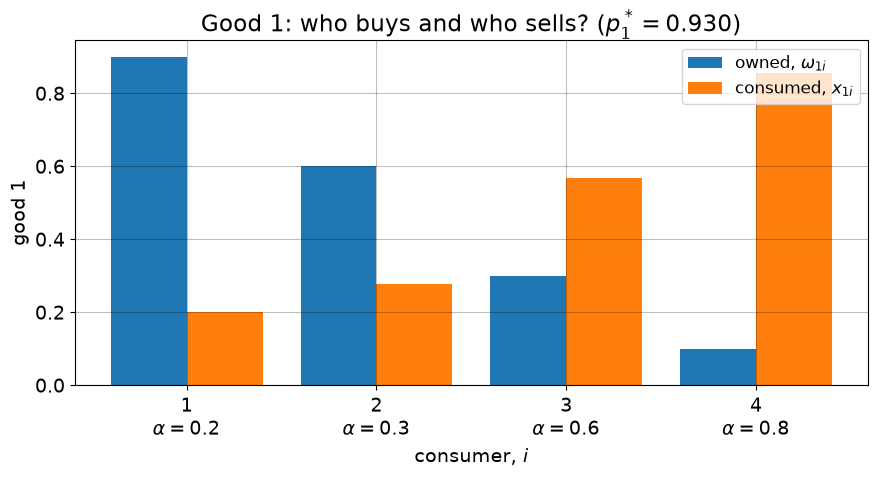


consumers 1 and 2 own a lot of good 1 but do not care much for it, so they sell.
consumers 3 and 4 are the other way around, so they buy. The price settles where
what the sellers offer is exactly what the buyers want.


In [9]:
import A3
A3.run()

## 4. <a id='toc4_'></a>[More than one equilibrium](#toc0_)

Back to **two** consumers, $A$ and $B$, and two goods, with one unit of each good in total and $p_2=1$ as the numeraire - exactly as in the lecture. The only thing we change is the **utility function**, from Cobb-Douglas to the **CES** form

$$ u(x_1,x_2;\alpha,\beta,\rho) = \left(\alpha x_1^{\rho} + \beta x_2^{\rho}\right)^{1/\rho}, \qquad \rho \neq 0 $$

The indifference curve for the utility level $u$, solved for $x_2$, is

$$ x_2 = \left(\frac{u^{\rho}-\alpha x_1^{\rho}}{\beta}\right)^{\frac{1}{\rho}} $$

and with $\sigma = \frac{1}{1-\rho}$ and $m = p_1\omega_1+\omega_2$ the demand functions are

$$ x_1(p_1,m) = \frac{\alpha^{\sigma}p_1^{-\sigma}\,m}{\alpha^{\sigma}p_1^{1-\sigma}+\beta^{\sigma}}, \qquad
   x_2(p_1,m) = \frac{\beta^{\sigma}\,m}{\alpha^{\sigma}p_1^{1-\sigma}+\beta^{\sigma}} $$

Excess demand and the equilibrium condition are unchanged,

$$ \varepsilon_1(p_1) = x_1^{A}(p_1,m^A) + x_1^{B}(p_1,m^B) - 1 = 0 $$

but this time there is **no formula** for $p_1^{\ast}$ - and, as you will see, no guarantee that there is only one of them either.

**Calibration.** $\alpha^A = \beta^B = 1$, $\beta^A = \alpha^B = (12/37)^3$ and $\rho^A = \rho^B = -2$. The endowments are $\omega_1^A = 1-10^{-8}$ and $\omega_2^A = 10^{-8}$, i.e. $A$ starts with all of good 1 and $B$ with all of good 2.

**Code.** The model is written for you in **[exchangeCES.py](exchangeCES.py)** - preferences, demand and excess demand, in the same style as [exchange.py](exchange.py) from the lecture. What is *missing* is the solvers, and that is what you write here:

```python
from exchangeCES import ExchangeEconomyCES,plot_indifference_A,plot_indifference_B

model = ExchangeEconomyCES()
print(model)
```

**Question:**

1. Make a figure with two panels: the demand for good 1 of each consumer, $x_1^{A}(p_1)$ and $x_1^{B}(p_1)$, and excess demand for good 1, $\varepsilon_1(p_1)$, for $p_1 \in$ `np.linspace(0.25,5,100)`. When is $\varepsilon_1(p_1) \approx 0$? **How many equilibria are there?**

2. Write the **tâtonnement** algorithm from the lecture as a function, with $\tau = 10^{-8}$, $\nu = 50$ and at most $K = 5000$ rounds:

    1. guess $p_1^{0}$ and set $k=0$
    2. calculate $\varepsilon_1^{k} = \varepsilon_1(p_1^{k})$
    3. if $|\varepsilon_1^{k}| < \tau$: stop and return $p_1^{\ast} = p_1^{k}$
    4. if $k > K$: stop and report that it did not converge
    5. set $p_1^{k+1} = p_1^{k} + \nu\varepsilon_1^{k}$
    6. increment $k$ and go back to 2

    Apply it for $p_1^{0} = 0.9$ and $p_1^{0} = 1.1$, and plot the sequences $p_1^{k}$ and $|\varepsilon_1^{k}|$. **Does the guess decide which equilibrium you find?**

3. Apply the same algorithm for all 50 guesses in $p_1^{0} \in$ `np.linspace(0.25,5,50)` and plot $p_1^{0}$ against the resulting $p_1^{\ast}$. **Do you find all the equilibria?**

4. Write a **dampened Newton-Raphson** algorithm with $\tau = 10^{-8}$, $\varphi = 0.1$, $\iota = 0.99$ and $K = 5000$. It is the same loop, except that steps 5-6 are replaced by

    1. calculate the slope $\Delta = \frac{\varepsilon_1(p_1^{k}+h)-\varepsilon_1^{k}}{h}$ for $h = 10^{-6}$
    2. set $p_1^{k+1} = p_1^{k} - \varphi\frac{\varepsilon_1^{k}}{\Delta}$
    3. if $p_1^{k+1} \leq 0$ instead set $p_1^{k+1} = \iota p_1^{k}$

    Apply it for the same 50 guesses and make the same figure. **Do you find all the equilibria now?** Why does this algorithm behave differently?

**Hints:**

* Excess demand is **tiny** here - never more than about $0.006$ in absolute value. That is why $\nu$ has to be as large as $50$, and why you have to look closely at the y-axis to see anything at all in question 1.
* Return *both* the last price and whether the algorithm converged, and collect the whole path in a list, `p1_path.append(p1)`, so you can plot it afterwards.
* A log y-axis cannot show an exact zero: use `np.fmax(np.abs(eps1_path),1e-16)`.
* Once you have found the equilibria in question 1, check that they are exactly $27/64$, $1$ and $64/27$.
* In question 4, think about what the *sign* of the slope $\Delta$ does to the step - and compare it with what the auctioneer does in step 5 above.

In [10]:
# write your own code here

Exchange economy with CES preferences:
  A: alpha = 1.0000, beta = 0.0341, rho = -2.00
  B: alpha = 0.0341, beta = 1.0000, rho = -2.00
  wA = (1.0000,0.0000) (what A owns)
  wB = (0.0000,1.0000) (what B owns)

--- question 1 ---



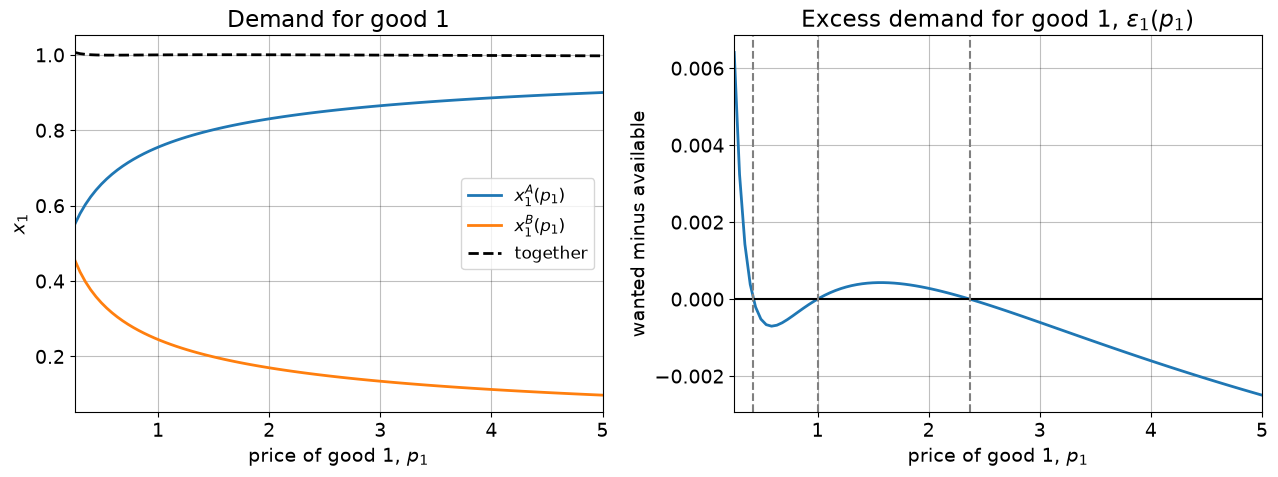

excess demand is *tiny* everywhere - never more than 0.0064 in absolute value - and it crosses zero three times.
there are three equilibria:
  p1* = 0.421875 with excess demand 6.58e-09
  p1* = 1.000000 with excess demand 0.00e+00
  p1* = 2.370370 with excess demand -2.78e-09

note that you have to look closely to see this: on a figure where the y-axis ran
from -1 to 1 the whole curve would look like a flat line lying on top of zero.

--- question 2 ---

from p1 = 0.90: converged = True after  34 rounds -> p1* = 0.42187628
from p1 = 1.10: converged = True after 292 rounds -> p1* = 2.37035615


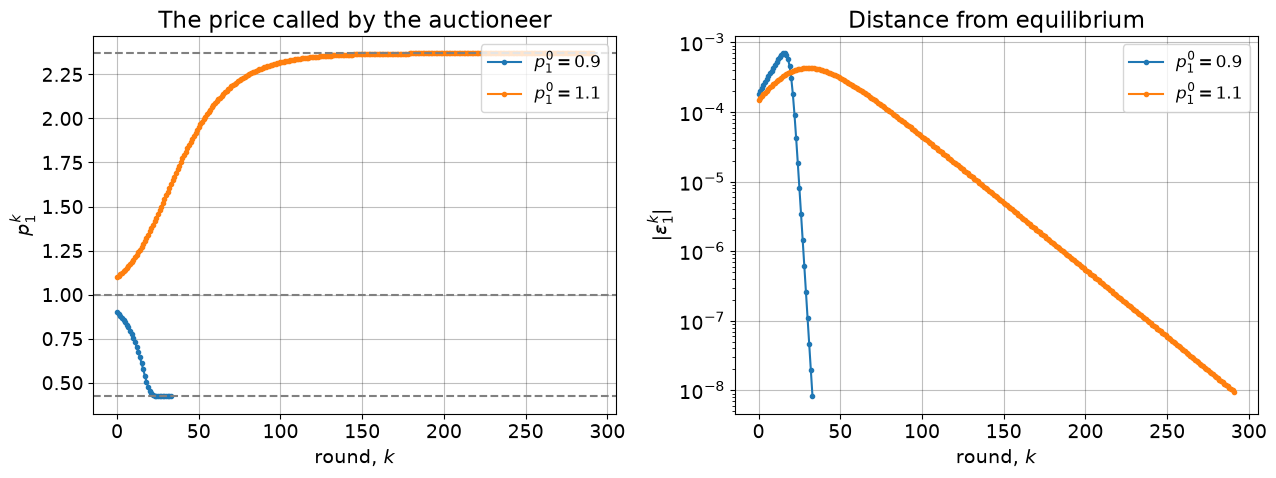


yes - the guess decides everything. Starting just below 1 the auctioneer walks
down to 27/64, starting just above it he walks up to 64/27. The algorithm always
moves the price in the direction excess demand points, and around p1 = 1 that
direction is *away* from the equilibrium.

--- question 3 ---



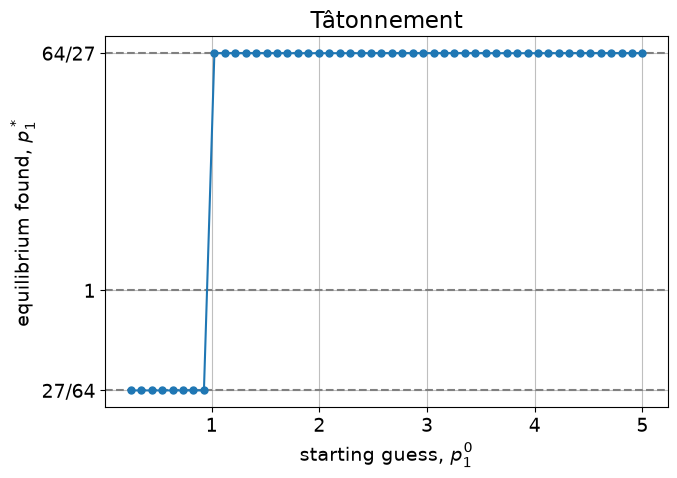

the algorithm ends in 2 different places:
  p1* = 0.4219 from 8 of the 50 guesses
  p1* = 2.3704 from 42 of the 50 guesses

no - the middle equilibrium, p1* = 1, is never found. Every single guess ends in
one of the two outer ones.

--- question 4 ---



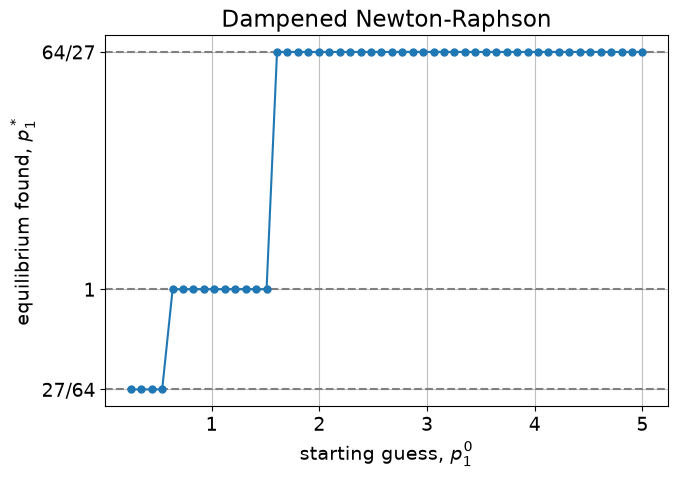

the algorithm ends in 3 different places:
  p1* = 0.4219 from 4 of the 50 guesses
  p1* = 1.0000 from 10 of the 50 guesses
  p1* = 2.3704 from 36 of the 50 guesses

yes - now all three are found, the middle one included.

why? Because Newton-Raphson does not care which *way* excess demand points, only
where the straight line through the current point crosses zero. Dividing by the
slope flips the step whenever the slope is positive, and that is exactly what goes
wrong for the auctioneer around p1 = 1.

note what all this means: "the" equilibrium is not always a single point. Which one
your code reports can depend on the algorithm and on where you started it - so a
number that comes out of a solver is not automatically *the* answer.


In [11]:
import A4
A4.run()